In [ ]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks', 'chest_xray.zip', 'G:', 'G']

In [12]:
!unzip -oq "/content/drive/MyDrive/chest_xray.zip" -d "/content/pneumonia_data"

In [13]:
import os
print(os.listdir("/content/pneumonia_data/chest_xray"))

['val', '__MACOSX', 'chest_xray', 'test', 'train']


In [14]:
import os

data_path = "/content/pneumonia_data/chest_xray"

print(os.listdir(data_path + "/train"))

['PNEUMONIA', 'NORMAL']


In [16]:

import tensorflow as tf

data_path = "/content/pneumonia_data/chest_xray"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_path + "/train",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_path + "/train",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    data_path + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Images loaded successfully!")


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Images loaded successfully!


In [17]:

import tensorflow as tf

# Load a pretrained image recognition model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Build our pneumonia classification model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

# Prepare the model for training
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Your pneumonia model is ready!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Your pneumonia model is ready!


In [18]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 292s 2s/step - accuracy: 0.8790 - loss: 0.2821 - val_accuracy: 0.9463 - val_loss: 0.1575
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 354s 2s/step - accuracy: 0.9509 - loss: 0.1434 - val_accuracy: 0.9511 - val_loss: 0.1346
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.9612 - loss: 0.1168 - val_accuracy: 0.9607 - val_loss: 0.1095
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - accuracy: 0.9621 - loss: 0.1059 - val_accuracy: 0.9636 - val_loss: 0.1006
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 289s 2s/step - accuracy: 0.9657 - loss: 0.1005 - val_accuracy: 0.9636 - val_loss: 0.0952


In [19]:

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))


20/20 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.8349 - loss: 0.4260
Test Accuracy: 83.49 %
Test Loss: 0.426


20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step
              precision    recall  f1-score   support

      NORMAL       0.97      0.58      0.72       234
   PNEUMONIA       0.80      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



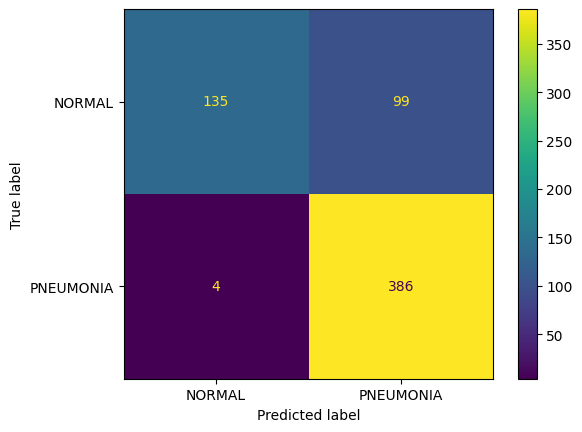

In [20]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Get the true labels from the test dataset
y_true = np.concatenate([
    labels.numpy().ravel() for images, labels in test_ds
]).astype(int)

# Get the model's predictions
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Display the evaluation metrics
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

# Display the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)
disp.plot()
plt.show()


In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
model.save('/content/drive/MyDrive/pneumonia_model.keras')

print("Model saved successfully!")

Model saved successfully!


In [26]:
import pickle

with open('/content/drive/MyDrive/pneumonia_history.pkl', 'wb') as f:
    pickle.dump(history.history, f)

print("Training history saved successfully!")

Training history saved successfully!


In [27]:
import os

print(os.path.exists('/content/drive/MyDrive/pneumonia_model.keras'))
print(os.path.exists('/content/drive/MyDrive/pneumonia_history.pkl'))

True
True


In [28]:

from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

report = classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
)

print(report)

with open(
    "/content/drive/MyDrive/pneumonia_baseline_report.txt",
    "w"
) as f:
    f.write(report)

print("Baseline report saved!")


20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step
              precision    recall  f1-score   support

      NORMAL       0.97      0.58      0.72       234
   PNEUMONIA       0.80      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624

Baseline report saved!


In [29]:

import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
])

print("Data augmentation is ready!")


Data augmentation is ready!


In [30]:

import tensorflow as tf

# Create a new model; keep the original model unchanged
base_model_v2 = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_v2.trainable = False

inputs_v2 = tf.keras.Input(shape=(224, 224, 3))

# Apply augmentation only during training
x = data_augmentation(inputs_v2)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model_v2(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)

outputs_v2 = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model_v2 = tf.keras.Model(inputs_v2, outputs_v2)

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Improved model is ready!")


Improved model is ready!


In [31]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop]
)


Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 343s 3s/step - accuracy: 0.7306 - loss: 0.5515 - val_accuracy: 0.8063 - val_loss: 0.4017
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 373s 2s/step - accuracy: 0.7783 - loss: 0.4563 - val_accuracy: 0.8715 - val_loss: 0.3358
Epoch 3/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.8131 - loss: 0.3973 - val_accuracy: 0.8926 - val_loss: 0.2924
Epoch 4/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.8426 - loss: 0.3549 - val_accuracy: 0.9022 - val_loss: 0.2634
Epoch 5/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 346s 3s/step - accuracy: 0.8565 - loss: 0.3237 - val_accuracy: 0.9175 - val_loss: 0.2431
Epoch 6/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 349s 3s/step - accuracy: 0.8771 - loss: 0.2886 - val_accuracy: 0.9223 - val_loss: 0.2284
Epoch 7/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 352s 3s/step - accuracy: 0.8924 - loss: 0.2708 - val_accuracy: 0.9271 - val_loss: 0.2175
Epoch 8/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.8977 - loss: 0.2600 - val_accuracy: 0.

In [32]:

model_v2.save("/content/drive/MyDrive/pneumonia_model_v2.keras")
print("Version 2 saved successfully!")


Version 2 saved successfully!


In [33]:

test_loss_v2, test_accuracy_v2 = model_v2.evaluate(test_ds)

print("Version 2 Test Loss:", test_loss_v2)
print("Version 2 Test Accuracy:", test_accuracy_v2 * 100, "%")


20/20 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.7500 - loss: 0.4781
Version 2 Test Loss: 0.47806280851364136
Version 2 Test Accuracy: 75.0 %


In [34]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob_v2 = model_v2.predict(test_ds)
y_pred_v2 = (y_prob_v2.ravel() >= 0.5).astype(int)

print("Class names:", test_ds.class_names)
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_v2,
    target_names=test_ds.class_names
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_v2))


20/20 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step
Class names: ['NORMAL', 'PNEUMONIA']

Classification Report:
              precision    recall  f1-score   support

      NORMAL       1.00      0.33      0.50       234
   PNEUMONIA       0.71      1.00      0.83       390

    accuracy                           0.75       624
   macro avg       0.86      0.67      0.67       624
weighted avg       0.82      0.75      0.71       624

Confusion Matrix:
[[ 78 156]
 [  0 390]]


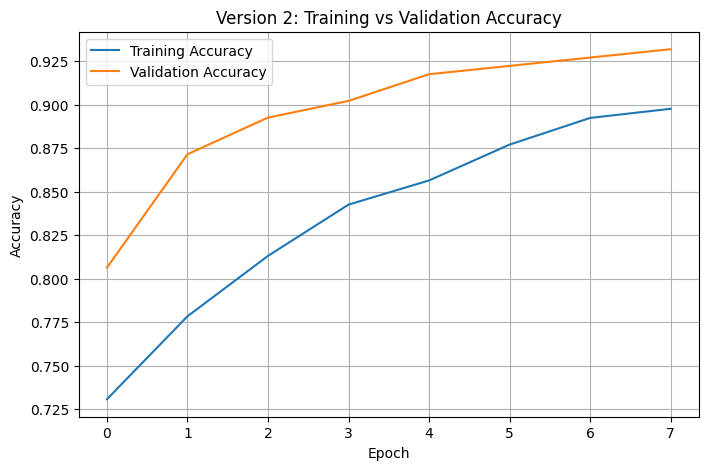

In [35]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_v2.history["accuracy"], label="Training Accuracy")
plt.plot(history_v2.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Version 2: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


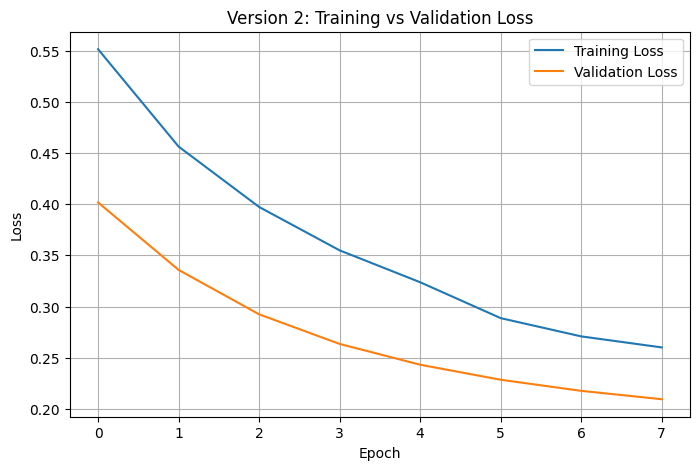

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_v2.history["loss"], label="Training Loss")
plt.plot(history_v2.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Version 2: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()



In [37]:

import os

dataset_path = "/content/pneumonia_data/chest_xray"

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()} folder:")
    split_path = os.path.join(dataset_path, split)

    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_path = os.path.join(split_path, class_name)

        if os.path.exists(class_path):
            print(class_name, ":", len(os.listdir(class_path)), "files")
        else:
            print(class_name, ": FOLDER NOT FOUND")




TRAIN folder:
NORMAL : 1341 files
PNEUMONIA : 3875 files

VAL folder:
NORMAL : 8 files
PNEUMONIA : 8 files

TEST folder:
NORMAL : 234 files
PNEUMONIA : 390 files
